Libraries imported successfully!
Upload your Employee Attrition CSV or Excel file:


Saving employee_attrition_cleaned_dataset.xlsx to employee_attrition_cleaned_dataset.xlsx

First 5 Records:


,Employee ID,Age,Gender,Department,Job Role,Monthly Income,Job Satisfaction,Work-Life Balance,Years at Company,Overtime,Performance Rating,Attrition
0,E001,29,Female,Sales,Sales Executive,42000,4,3,1,Yes,3,Yes
1,E002,34,Male,R&D,Data Analyst,58000,3,4,5,No,4,No
2,E003,41,Female,HR,HR Executive,51000,2,2,8,No,3,No
3,E004,27,Male,Sales,Sales Executive,38000,1,2,0,Yes,2,Yes
4,E005,31,Female,IT,Software Developer,65000,4,3,3,No,4,No



Dataset Shape: (14, 12)

Column Names:
['Employee ID', 'Age', 'Gender', 'Department', 'Job Role', 'Monthly Income', 'Job Satisfaction', 'Work-Life Balance', 'Years at Company', 'Overtime', 'Performance Rating', 'Attrition']

Missing Values:
Employee ID           0
Age                   0
Gender                0
Department            0
Job Role              0
Monthly Income        0
Job Satisfaction      0
Work-Life Balance     0
Years at Company      0
Overtime              0
Performance Rating    0
Attrition             0
dtype: int64

Duplicate Records: 0

Cleaned Dataset Shape: (14, 12)

Attrition Counts:
Attrition
No     11
Yes     3
Name: count, dtype: int64


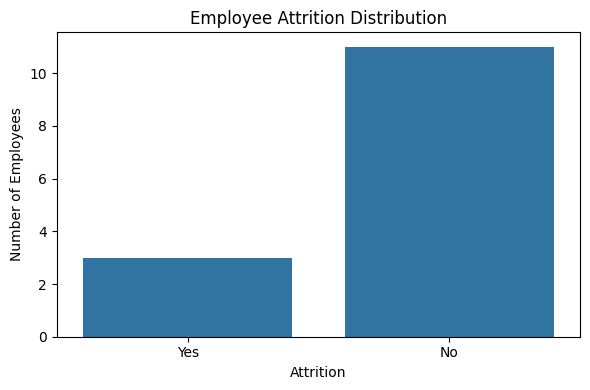


Attrition Percentage:
Attrition
No     78.57
Yes    21.43
Name: proportion, dtype: float64


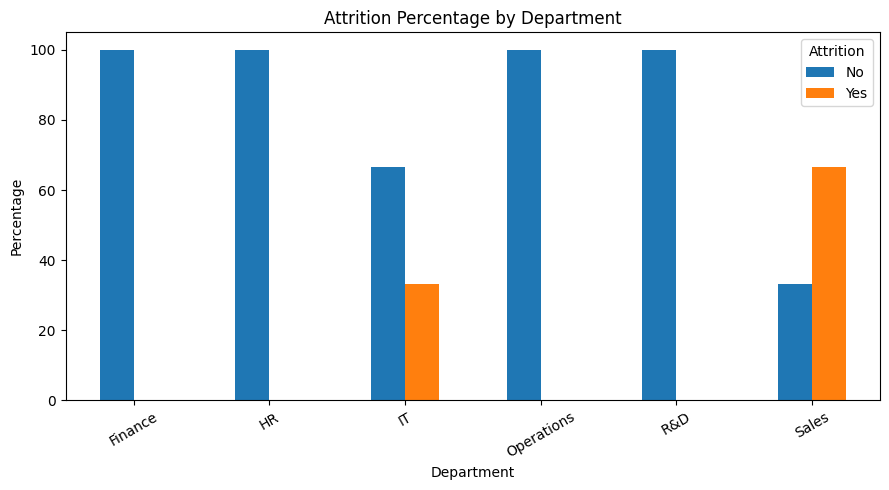

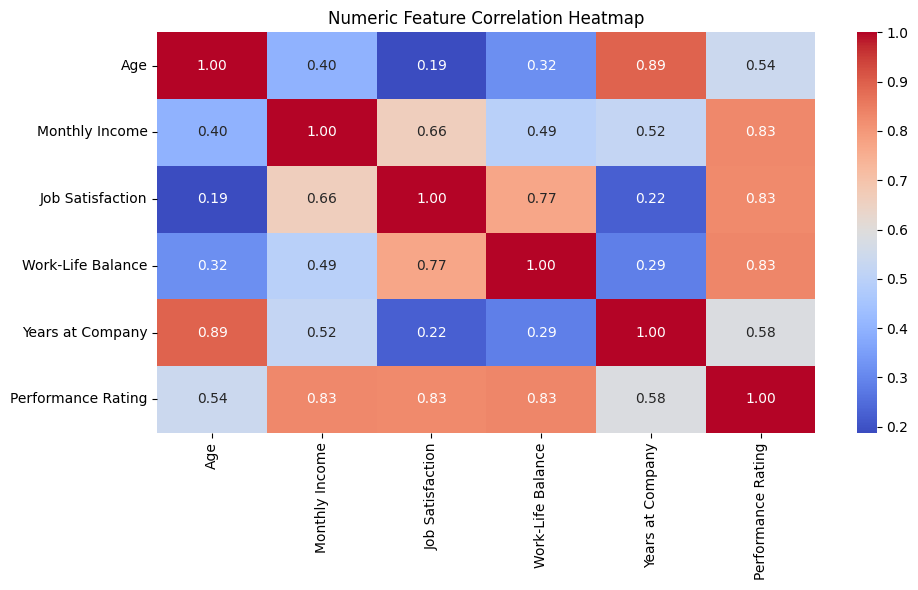


Target Classes: ['No', 'Yes']
Features Used: ['Employee ID', 'Age', 'Gender', 'Department', 'Job Role', 'Monthly Income', 'Job Satisfaction', 'Work-Life Balance', 'Years at Company', 'Overtime', 'Performance Rating']

Training Records: 11
Testing Records: 3

Logistic Regression
Accuracy: 0.6667
Precision: 0.4444
Recall: 0.6667
F1 Score: 0.5333
ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       0.67      1.00      0.80         2
         Yes       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



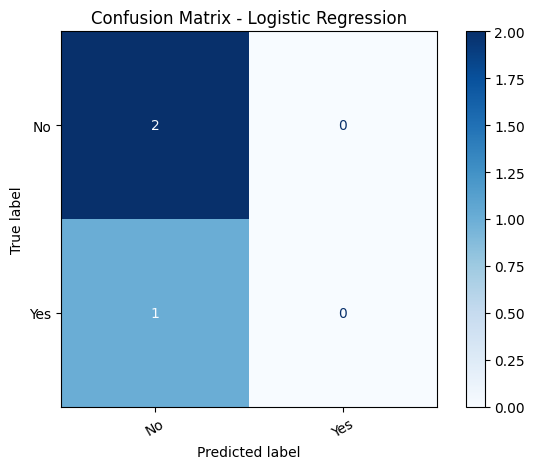


Decision Tree
Accuracy: 0.6667
Precision: 0.4444
Recall: 0.6667
F1 Score: 0.5333
ROC-AUC: 0.5

Classification Report:
              precision    recall  f1-score   support

          No       0.67      1.00      0.80         2
         Yes       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



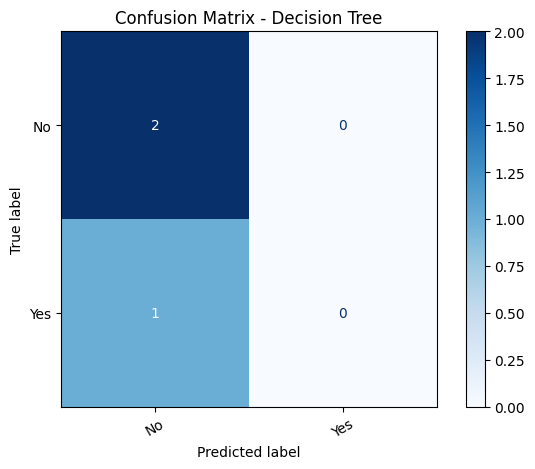


Random Forest
Accuracy: 0.6667
Precision: 0.4444
Recall: 0.6667
F1 Score: 0.5333
ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       0.67      1.00      0.80         2
         Yes       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



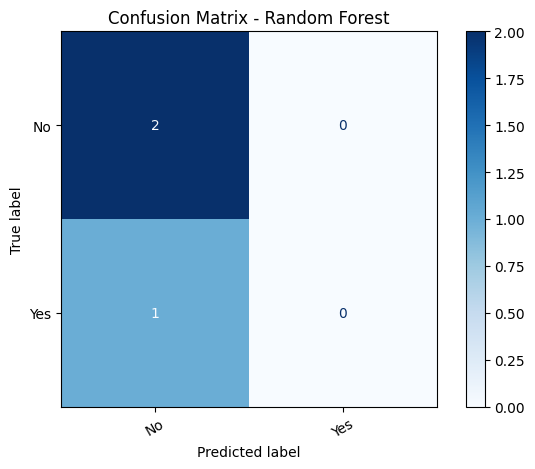


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6667,0.4444,0.6667,0.5333,1.0
1,Decision Tree,0.6667,0.4444,0.6667,0.5333,0.5
2,Random Forest,0.6667,0.4444,0.6667,0.5333,1.0


Best Model by Weighted F1 Score: Logistic Regression


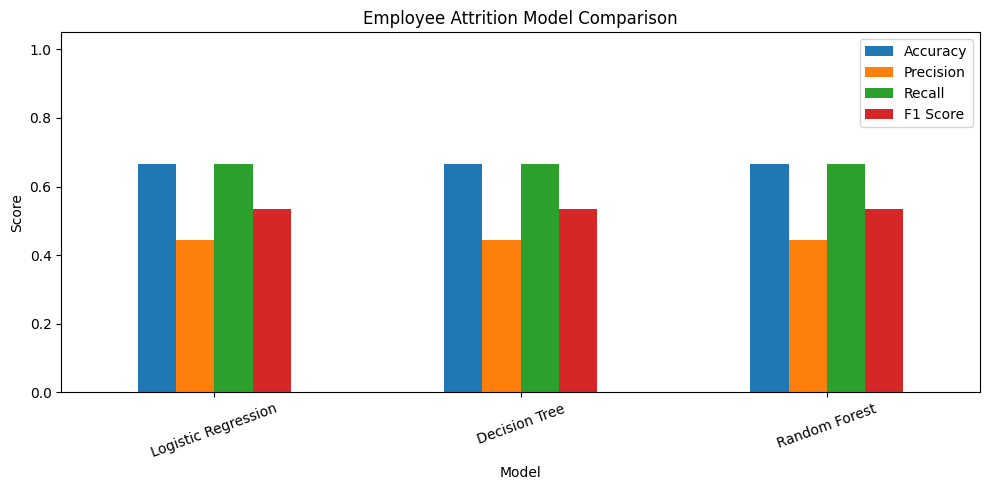

<Figure size 700x500 with 0 Axes>

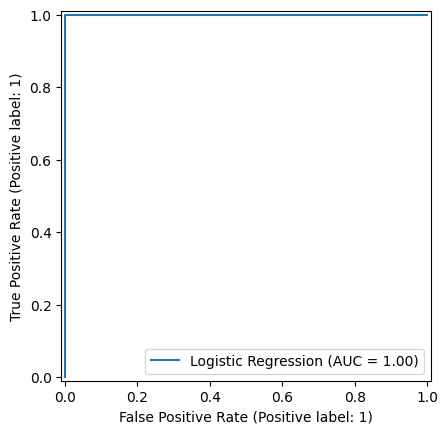

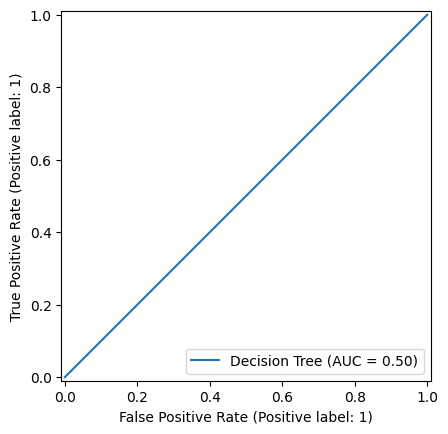

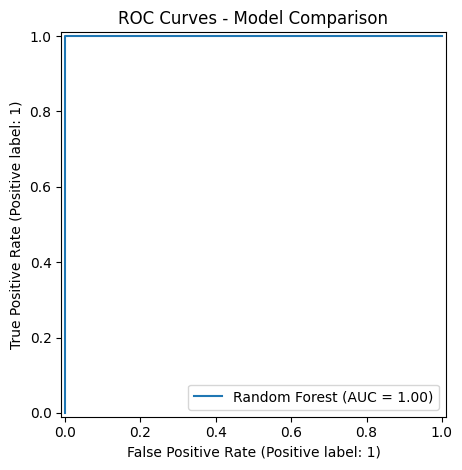


Top Features - Decision Tree


,Feature,Importance
0,numeric__Age,1.0
1,numeric__Monthly Income,0.0
2,numeric__Job Satisfaction,0.0
3,numeric__Work-Life Balance,0.0
4,numeric__Years at Company,0.0
5,numeric__Performance Rating,0.0
6,categorical__Employee ID_E002,0.0
7,categorical__Employee ID_E003,0.0
8,categorical__Employee ID_E004,0.0
9,categorical__Employee ID_E005,0.0


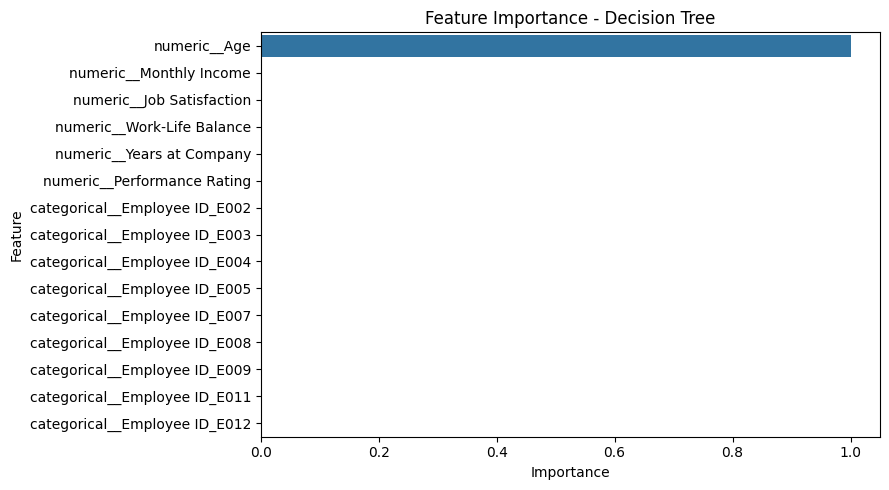


Top Features - Random Forest


,Feature,Importance
5,numeric__Performance Rating,0.163592
0,numeric__Age,0.162265
4,numeric__Years at Company,0.132135
3,numeric__Work-Life Balance,0.109823
32,categorical__Overtime_Yes,0.101912
2,numeric__Job Satisfaction,0.069509
31,categorical__Overtime_No,0.048938
8,categorical__Employee ID_E004,0.042976
30,categorical__Job Role_Software Developer,0.031609
1,numeric__Monthly Income,0.027936


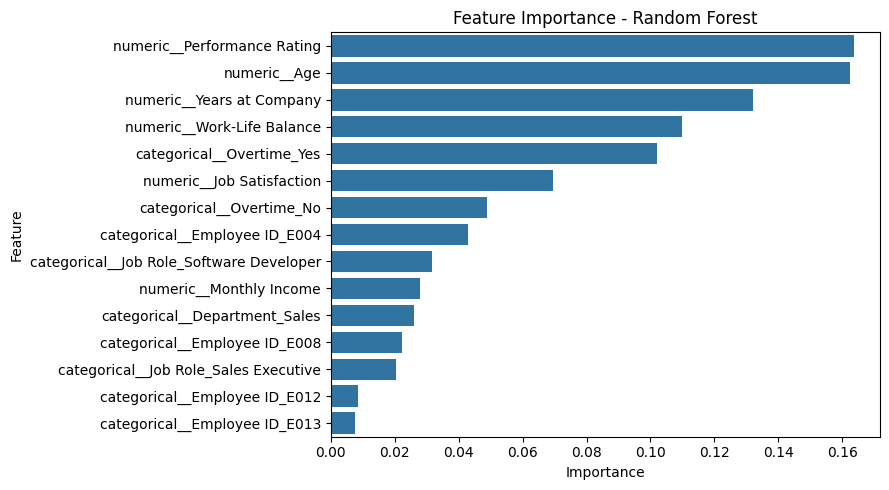

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT COMPLETED SUCCESSFULLY!
Use the actual output and graphs in your project report.


In [1]:

# EMPLOYEE ATTRITION ANALYSIS AND PREDICTION

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
)

print("Libraries imported successfully!")

# 2. Upload Dataset
print("Upload your Employee Attrition CSV or Excel file:")
uploaded = files.upload()
file_path = next(iter(uploaded.keys()))

if file_path.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_path)
else:
    df = pd.read_csv(file_path)

# 3. Inspect Dataset
df.columns = df.columns.astype(str).str.strip()

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# 4. Clean Dataset
df = df.drop_duplicates().copy()

# Find Attrition column, ignoring capitalisation/spaces
target = next(
    (c for c in df.columns if c.strip().lower() == "attrition"),
    None
)

if target is None:
    raise ValueError(
        "Attrition column not found. Check your dataset column names."
    )

df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(str).str.strip()
df = df[df[target] != ""].copy()

if df[target].nunique() < 2:
    raise ValueError("Attrition must contain at least two classes.")

print("\nCleaned Dataset Shape:", df.shape)
print("\nAttrition Counts:")
print(df[target].value_counts())

# 5. Exploratory Data Analysis (EDA)

# Attrition distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

# Attrition percentages
print("\nAttrition Percentage:")
print((df[target].value_counts(normalize=True) * 100).round(2))

# Department-wise attrition, if available
dept_col = next(
    (c for c in df.columns if c.lower() == "department"),
    None
)

if dept_col:
    dept_data = pd.crosstab(
        df[dept_col], df[target], normalize="index"
    ) * 100

    dept_data.plot(kind="bar", figsize=(9, 5))
    plt.title("Attrition Percentage by Department")
    plt.ylabel("Percentage")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Numeric correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(), annot=True,
        cmap="coolwarm", fmt=".2f"
    )
    plt.title("Numeric Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# 6. Prepare Features and Target
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Remove common ID, constant, and leakage-prone columns
drop_cols = [
    c for c in X.columns
    if c.strip().lower() in [
        "employeenumber", "employeeid", "id",
        "employeecount", "over18", "standardhours"
    ]
]

X = X.drop(columns=drop_cols, errors="ignore")

# Remove columns containing no usable values
X = X.dropna(axis=1, how="all")

# Remove constant columns
constant_cols = [
    c for c in X.columns if X[c].nunique(dropna=True) <= 1
]
X = X.drop(columns=constant_cols, errors="ignore")

if X.shape[1] == 0:
    raise ValueError("No usable feature columns remain.")

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nTarget Classes:", list(label_encoder.classes_))
print("Features Used:", X.columns.tolist())

# 7. Train-Test Split
class_counts = pd.Series(y_encoded).value_counts()
stratify_values = y_encoded if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=stratify_values
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

# 8. Preprocess Numeric and Categorical Features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 9. Create Three ML Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10,
        random_state=42, class_weight="balanced"
    )
}

results = []
trained_models = {}

# 10. Train and Evaluate Models
for name, classifier in models.items():
    print("\n" + "=" * 50)
    print(name)

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="weighted",
        zero_division=0
    )

    auc = np.nan
    if len(label_encoder.classes_) == 2:
        try:
            probabilities = model.predict_proba(X_test)[:, 1]
            if len(np.unique(y_test)) == 2:
                auc = roc_auc_score(y_test, probabilities)
        except (ValueError, IndexError):
            pass

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4) if not np.isnan(auc) else "N/A")

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=[str(c) for c in label_encoder.classes_],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        labels=np.arange(len(label_encoder.classes_)),
        display_labels=label_encoder.classes_,
        cmap="Blues",
        xticks_rotation=30
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

# 11. Compare Models
comparison = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
)

print("\nMODEL COMPARISON")
display(comparison.round(4))

best_name = comparison.iloc[0]["Model"]
print("Best Model by Weighted F1 Score:", best_name)

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Employee Attrition Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 12. ROC Curve (Binary Classification)
if len(label_encoder.classes_) == 2 and len(np.unique(y_test)) == 2:
    plt.figure(figsize=(7, 5))
    for name, model in trained_models.items():
        RocCurveDisplay.from_estimator(
            model, X_test, y_test, name=name
        )
    plt.title("ROC Curves - Model Comparison")
    plt.tight_layout()
    plt.show()

# 13. Feature Importance (Tree Models)
for name in ["Decision Tree", "Random Forest"]:
    model = trained_models[name]
    fitted_preprocessor = model.named_steps["preprocessor"]
    classifier = model.named_steps["classifier"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    print(f"\nTop Features - {name}")
    display(importance_df)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=importance_df,
        x="Importance", y="Feature"
    )
    plt.title(f"Feature Importance - {name}")
    plt.tight_layout()
    plt.show()

# 14. Save Results
comparison.to_csv("employee_attrition_model_comparison.csv", index=False)
files.download("employee_attrition_model_comparison.csv")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("Use the actual output and graphs in your project report.")
